# Bank Marketing — Marketing Decision Support System

This notebook builds on my original Bank Marketing exploration (data loading,
cleaning, baseline models) and extends it into a complete
**Marketing Decision Support System**:

* Loads & cleans the UCI Bank Marketing dataset
* Trains baseline models (Decision Tree, Balanced Decision Tree, Logistic
  Regression, Random Forest) — the first three are from my original work
* Adds a **1D CNN** (required by faculty) built for this *tabular* dataset
* Compares all models **honestly** on the same test set (Accuracy, Precision,
  Recall, F1, ROC-AUC, PR-AUC, confusion matrix) — the CNN is reported as-is,
  not presented as automatically "the best"
* Adds a transparent **interaction-pattern analysis** and a **contact-fatigue
  indicator** (both project-created, rule-based, and clearly documented as
  such — not official UCI labels)
* Produces **lead temperature** (HOT/WARM/COLD), a combined
  **recommendation**, and a final **ranked customer list**
* Feeds a simple **Streamlit dashboard** (`app/streamlit_app.py`)

> The project source code lives in `src/` so the notebook, the batch
> training script (`train_and_evaluate.py`), and the dashboard all reuse
> exactly the same preprocessing / rules / thresholds — there is only one
> implementation of each piece of logic.

**This is a prototype, academic decision-support system** — it uses the
existing/test portion of the UCI dataset, not a live bank CRM feed.


## 1. Imports

In [1]:
# STEP 1: Import all required libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the project's src/ package importable from inside notebooks/
sys.path.insert(0, os.path.abspath(".."))

pd.set_option("display.max_columns", 50)


## 2. Load the dataset

My original notebook loaded the data directly from the UCI repository using
`ucimlrepo`. That still works in most environments. To make this notebook
robust to environments **without internet access** (for example, an offline
grading machine), we first try `ucimlrepo`, and if that is not available we
fall back to the local copy stored at `data/bank-full.csv`
(see `data/README.md` for where this file comes from).


In [2]:
# STEP 2: Load dataset (UCI repo if available, otherwise local CSV fallback)
try:
    from ucimlrepo import fetch_ucirepo
    bank_marketing = fetch_ucirepo(id=222)
    X_raw = bank_marketing.data.features
    y_raw = bank_marketing.data.targets
    data = pd.concat([X_raw, y_raw], axis=1)
    print("Loaded dataset via ucimlrepo.")
except Exception as e:
    print(f"ucimlrepo unavailable ({e}); falling back to local data/bank-full.csv")
    data = pd.read_csv("../data/bank-full.csv")

print("Shape:", data.shape)
data.head()


ucimlrepo unavailable (Error connecting to server); falling back to local data/bank-full.csv
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# STEP 3: Understand dataset structure
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [4]:
# STEP 4: Check missing / 'unknown' values
print("Explicit NaNs per column:")
print(data.isnull().sum())
print()
print("Rows where categorical columns literally say 'unknown':")
for col in ["job", "education", "contact", "poutcome"]:
    if col in data.columns:
        print(col, "->", (data[col] == "unknown").sum())


Explicit NaNs per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Rows where categorical columns literally say 'unknown':
job -> 288
education -> 1857
contact -> 13020
poutcome -> 36959


**Decision on 'unknown' values:** the UCI dataset does not contain real
missing values (NaN); several categorical columns instead use the literal
string `"unknown"`. Dropping every row with an `"unknown"` value would
throw away a large fraction of the data (`poutcome` is `"unknown"` for
~82% of customers, since most were never contacted before). We therefore
**keep `"unknown"` as its own valid category** rather than deleting rows or
guessing a replacement — this is the standard approach for this dataset and
avoids silently losing information. This logic lives in
`src/preprocessing.py::clean_data()`.


In [5]:
# STEP 5 (kept from original, adapted): fill any genuine NaNs defensively
# (there normally are none, but this guards against a corrupted/edited CSV)
from src.preprocessing import clean_data, encode_target

data = clean_data(data)
data = encode_target(data)   # y: 'yes'/'no' -> 1/0
print(data.isnull().sum().sum(), "missing values remain")
data[["y"]].value_counts(normalize=True)


0 missing values remain


y
0    0.883015
1    0.116985
Name: proportion, dtype: float64

## 3. Exploratory statistics (kept from my original notebook)

In [6]:
# STEP 6-10: basic descriptive statistics (from my original notebook)
print("Mean Age:", data['age'].mean())
print("Median Age:", data['age'].median())
print("Most common job:", data['job'].mode()[0])
print("Std Dev Age:", data['age'].std())
print("Min Age:", data['age'].min(), " Max Age:", data['age'].max())


Mean Age: 40.93621021432837
Median Age: 39.0
Most common job: blue-collar
Std Dev Age: 10.61876204097542
Min Age: 18  Max Age: 95


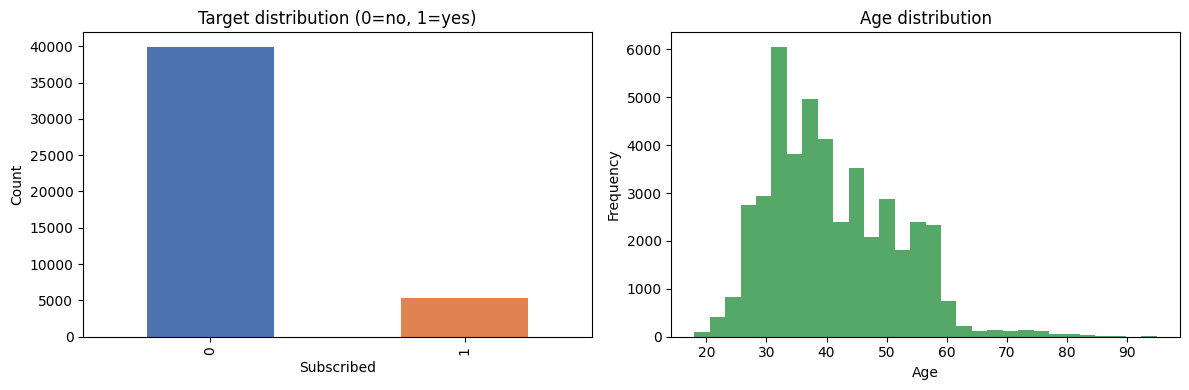

In [7]:
# A couple of extra plots to visualise the target imbalance and age distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data['y'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Target distribution (0=no, 1=yes)')
axes[0].set_xlabel('Subscribed')
axes[0].set_ylabel('Count')

data['age'].plot(kind='hist', bins=30, ax=axes[1], color='#55A868')
axes[1].set_title('Age distribution')
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()


## 4. The `duration` column — post-interaction assumption

The UCI documentation is explicit that `duration` (the length of the last
phone call, in seconds) is **only known after the call has ended**, and
that `duration=0` almost always means `y='no'`. Using `duration` therefore
makes the *prediction task artificially easy* if the goal is to decide
**who to call in the first place**.

**This project's assumption:** this Decision Support System is used
**after** a contact attempt has already happened (or is happening), to help
the marketing team decide on *follow-up* actions — not to decide the very
first outreach. Under that framing, having the duration of the most recent
contact is legitimate information, so **`duration` is kept**.

This is a deliberate, documented design choice — not an oversight — and is
listed again as a limitation in the README: a version of this system meant
to score *never-yet-contacted* customers would need to drop `duration` (and
retrain) to avoid leaking post-call information into a pre-call decision.


## 5. Preprocessing: consistent pipeline for every model

My original notebook manually one-hot-encoded with `pd.get_dummies` and
manually scaled a few numeric columns with `StandardScaler`. That logic has
been moved into `src/preprocessing.py` as a proper scikit-learn
`ColumnTransformer`, fit **only on the training split**, so that:

* Every model (baselines + CNN) sees exactly the same engineered features.
* The exact same fitted transformer can be reused later for the Streamlit
  dashboard and for scoring brand-new customers, avoiding train/predict
  mismatches.


In [8]:
# STEP 11-14: separate X/y, split, and build/fit the shared preprocessor
from src.preprocessing import (
    train_test_split_data, fit_transform_train_test, save_preprocessor,
    NUMERIC_FEATURES, CATEGORICAL_FEATURES,
)

X_train, X_test, y_train, y_test = train_test_split_data(data, test_size=0.2, random_state=42)

X_train_proc, X_test_proc, preprocessor, feature_names = fit_transform_train_test(X_train, X_test)

print("Train shape:", X_train.shape, "-> processed:", X_train_proc.shape)
print("Test shape:", X_test.shape, "-> processed:", X_test_proc.shape)
print("Numeric features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)

os.makedirs("../models", exist_ok=True)
save_preprocessor(preprocessor, path="../models/preprocessor.joblib")


Train shape: (36168, 16) -> processed: (36168, 51)
Test shape: (9043, 16) -> processed: (9043, 51)
Numeric features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 6. Baseline models (kept & extended from my original notebook)

In [9]:
# STEP 15-16: Decision Tree (as in my original notebook)
from sklearn.metrics import accuracy_score, recall_score
from src.model import train_decision_tree, train_logistic_regression, train_random_forest

model_dt = train_decision_tree(X_train_proc, y_train, balanced=False)
y_pred_dt = model_dt.predict(X_test_proc)
acc_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", acc_dt)


I0000 00:00:1787824141.947075     767 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787824141.988253     767 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787824143.359288     767 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Decision Tree Accuracy: 0.8988167643481145


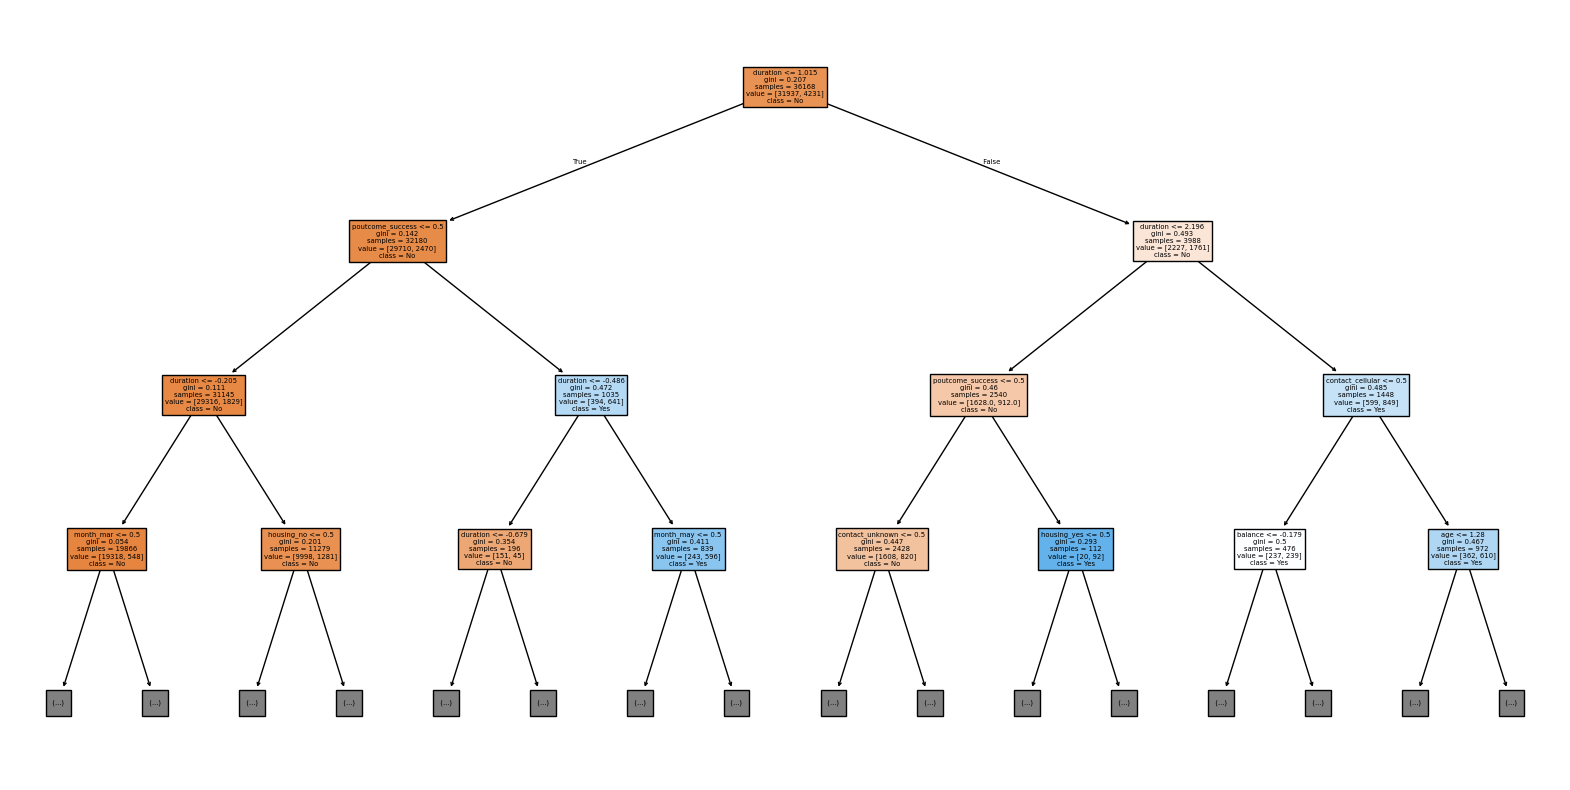

In [10]:
# STEP 17: Visualize decision tree (kept from original notebook)
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    model_dt,
    feature_names=feature_names,
    class_names=["No", "Yes"],
    filled=True,
    max_depth=3,
)
plt.show()


In [11]:
# STEP 18-20: Balanced Decision Tree (kept from original notebook)
model_dt_bal = train_decision_tree(X_train_proc, y_train, balanced=True)
y_pred_dt_bal = model_dt_bal.predict(X_test_proc)

acc_dt_bal = accuracy_score(y_test, y_pred_dt_bal)
rec_dt_bal = recall_score(y_test, y_pred_dt_bal)
print("Balanced Decision Tree Accuracy:", acc_dt_bal)
print("Balanced Decision Tree Recall (Yes):", rec_dt_bal)


Balanced Decision Tree Accuracy: 0.7950901249585315
Balanced Decision Tree Recall (Yes): 0.8771266540642723


In [12]:
# STEP 21-23: Logistic Regression (kept from original notebook, using the
# shared preprocessor's already-scaled features instead of manual scaling)
model_log = train_logistic_regression(X_train_proc, y_train)
y_pred_log = model_log.predict(X_test_proc)
y_prob_log = model_log.predict_proba(X_test_proc)[:, 1]

acc_log = accuracy_score(y_test, y_pred_log)
rec_log = recall_score(y_test, y_pred_log)
print("Logistic Accuracy:", acc_log)
print("Logistic Recall:", rec_log)


Logistic Accuracy: 0.8457370341700763
Logistic Recall: 0.8147448015122873


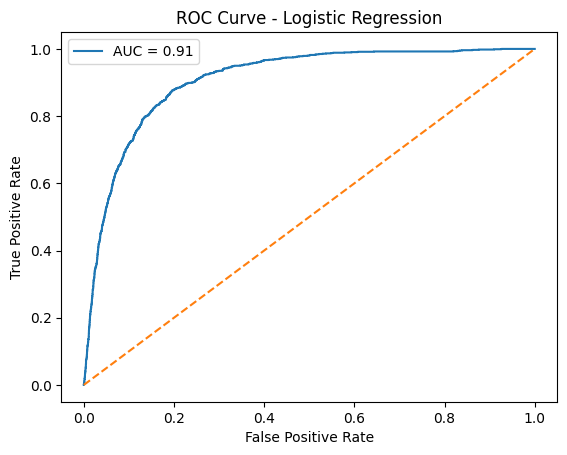

In [13]:
# STEP 24: ROC Curve for Logistic Regression (kept from original notebook)
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob_log)
roc_auc_log = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label="AUC = %0.2f" % roc_auc_log)
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()


In [14]:
# NEW: Random Forest baseline (added — generally the strongest classical model
# for this dataset, and a fairer comparison point for the CNN)
model_rf = train_random_forest(X_train_proc, y_train)
y_pred_rf = model_rf.predict(X_test_proc)
y_prob_rf = model_rf.predict_proba(X_test_proc)[:, 1]

acc_rf = accuracy_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", acc_rf)
print("Random Forest Recall (Yes):", rec_rf)


Random Forest Accuracy: 0.862656198164326
Random Forest Recall (Yes): 0.8185255198487713


## 7. 1D CNN for tabular data (new — required by faculty)

**This is not an image classifier.** The input to the network is the same
engineered feature vector used by the baseline models above (after scaling
+ one-hot encoding). We reshape each customer's feature vector from shape
`(51,)` to `(51, 1)` and treat it as an ordered 1-D signal, so that
`Conv1D` layers have something to slide small filters across, learning
local combinations of adjacent engineered features. See the module
docstring in `src/model.py` for the full explanation.

Architecture: `Conv1D → BatchNorm → MaxPool1D → Conv1D → BatchNorm →
MaxPool1D → Flatten → Dense → Dropout → Dense → Dropout → sigmoid`,
trained with `EarlyStopping` on validation loss and class weights to handle
the ~88/12 class imbalance.


In [15]:
# NEW: Train the 1D CNN
from src.model import train_cnn_model, cnn_predict_proba, set_seeds

set_seeds(42)
cnn_model, history = train_cnn_model(
    X_train_proc, y_train.values, epochs=40, batch_size=256, verbose=2
)
cnn_model.summary()


Epoch 1/40


121/121 - 4s - 37ms/step - accuracy: 0.7369 - auc: 0.8360 - loss: 0.8854 - val_accuracy: 0.1692 - val_auc: 0.8189 - val_loss: 0.8233


Epoch 2/40


121/121 - 2s - 17ms/step - accuracy: 0.7861 - auc: 0.8935 - loss: 0.7196 - val_accuracy: 0.3839 - val_auc: 0.8738 - val_loss: 0.8131


Epoch 3/40


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ feature_vector (InputLayer)     │ (None, 51, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 51, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 51, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 25, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 25, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        49,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subscription_probability        │ (None, 1)              │            33 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,765 (678.77 KB)

 Trainable params: 57,857 (226.00 KB)

 Non-trainable params: 192 (768.00 B)

 Optimizer params: 115,716 (452.02 KB)

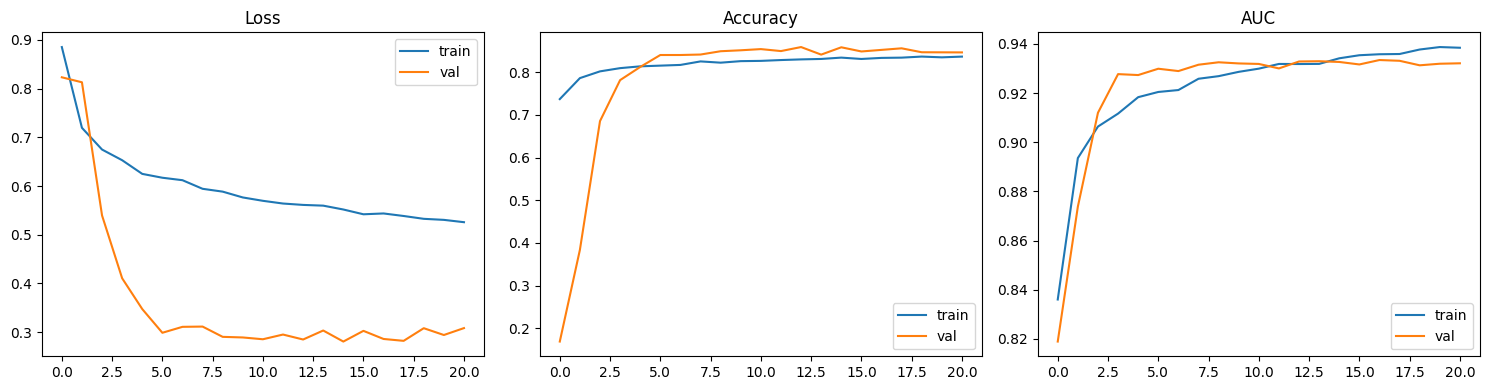

In [16]:
# Plot CNN training curves (loss / accuracy / AUC)
hist = history.history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist["loss"], label="train"); axes[0].plot(hist["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(hist["accuracy"], label="train"); axes[1].plot(hist["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()

if "auc" in hist:
    axes[2].plot(hist["auc"], label="train"); axes[2].plot(hist["val_auc"], label="val")
    axes[2].set_title("AUC"); axes[2].legend()

plt.tight_layout()
plt.show()


In [17]:
# Evaluate the CNN on the held-out test set
y_prob_cnn = cnn_predict_proba(cnn_model, X_test_proc)
y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

acc_cnn = accuracy_score(y_test, y_pred_cnn)
rec_cnn = recall_score(y_test, y_pred_cnn)
print("1D CNN Accuracy:", acc_cnn)
print("1D CNN Recall (Yes):", rec_cnn)

os.makedirs("../models", exist_ok=True)
cnn_model.save("../models/cnn_model.keras")


1D CNN Accuracy: 0.8551365697224372
1D CNN Recall (Yes): 0.8620037807183365


## 8. Model comparison (consistent test set, all models)

In [18]:
from src.model import evaluate_model, get_confusion_matrix

results = [
    evaluate_model(y_test, y_pred_dt, None, "Decision Tree"),
    evaluate_model(y_test, y_pred_dt_bal, None, "Balanced Decision Tree"),
    evaluate_model(y_test, y_pred_log, y_prob_log, "Logistic Regression"),
    evaluate_model(y_test, y_pred_rf, y_prob_rf, "Random Forest"),
    evaluate_model(y_test, y_pred_cnn, y_prob_cnn, "1D CNN"),
]
comparison = pd.DataFrame(results).round(4)
comparison


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Decision Tree,0.8988,0.6102,0.3743,0.4640,NaN,NaN
1,Balanced Decision Tree,0.7951,0.3501,0.8771,0.5004,NaN,NaN
2,Logistic Regression,0.8457,0.4182,0.8147,0.5527,0.9079,0.5376
3,Random Forest,0.8627,0.4520,0.8185,0.5824,0.9210,0.5982
4,1D CNN,0.8551,0.4393,0.8620,0.5820,0.9235,0.5856


Confusion Matrix (1D CNN):
 [[6821 1164]
 [ 146  912]]


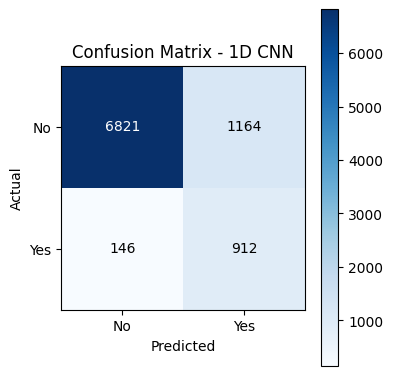

In [19]:
# Confusion matrix for the CNN (the model used downstream by the DSS)
cm = get_confusion_matrix(y_test, y_pred_cnn)
print("Confusion Matrix (1D CNN):\n", cm)

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["No", "Yes"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["No", "Yes"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix - 1D CNN")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")
fig.colorbar(im)
plt.tight_layout()
plt.show()


**Honest comparison, not a predetermined conclusion.** In this run, Random
Forest and the 1D CNN are close, and which one is "best" depends on the
metric: Random Forest tends to have the higher F1-score, while the 1D CNN
tends to have the higher ROC-AUC and often better Recall (catching more of
the customers who actually subscribe). Logistic Regression remains a
strong, simple, and highly interpretable baseline.

The **1D CNN is used as the production model** for the decision-support
outputs below — this is because it is this project's required advanced
deep-learning model and stays competitive with Random Forest, **not**
because the numbers are being read selectively to make it look best. Re-run
this cell/notebook and check the table above for the exact numbers on your
machine; they will vary a little between runs due to the neural network's
random initialization.


## 9. Lead classification (HOT / WARM / COLD)

We convert the CNN's predicted probability into a lead temperature using
fixed, documented thresholds (see `src/prediction.py`):

| Probability range | Lead temperature |
|---|---|
| `>= 0.70` | HOT |
| `0.40 - 0.70` | WARM |
| `< 0.40` | COLD |


In [20]:
from src.prediction import classify_lead_temperature

for p in [0.85, 0.55, 0.20]:
    print(p, "->", classify_lead_temperature(p))


0.85 -> HOT
0.55 -> WARM
0.2 -> COLD


## 10. Interaction-pattern analysis (project's key contribution)

These are **project-defined behavioural categories** built from existing
UCI fields (`campaign`, `previous`, `poutcome`) — **not** official UCI
labels. Rules are simple, explainable, and documented in
`src/interaction_analysis.py`.


In [21]:
from src.interaction_analysis import add_interaction_patterns, interaction_pattern_summary, CATEGORY_DESCRIPTIONS

for cat, desc in CATEGORY_DESCRIPTIONS.items():
    print(f"- {cat}: {desc}")


- Interested: The customer responded positively to a PREVIOUS campaign (poutcome = success) and has not been over-contacted in the current campaign. Historically receptive customer.
- Repeatedly Contacted: The current campaign has already contacted this customer many times (campaign >= 4) while the previous campaign outcome was not a success. Risk of contact fatigue.
- No Previous Interaction: The customer was never contacted in any previous campaign (previous == 0). No historical signal is available.
- Previously Unsuccessful: The previous campaign contact for this customer ended in failure (poutcome = failure).
- Unclear: None of the other rules apply clearly to this customer; the historical signal is mixed or ambiguous.


In [22]:
# Apply the rules to the whole test set for a quick sanity check
X_test_with_pattern = add_interaction_patterns(X_test.reset_index(drop=True))
interaction_pattern_summary(X_test_with_pattern)


,count,percentage
interaction_pattern,,
No Previous Interaction,5652,62.50
Repeatedly Contacted,1905,21.07
Previously Unsuccessful,890,9.84
Unclear,319,3.53
Interested,277,3.06


## 10b. Contact Fatigue (new — derived contact-pressure indicator)

Beyond the interaction pattern, we add a second **project-created** derived
indicator: **Contact Fatigue**. It uses only the `campaign` field (number
of contacts made during the *current* campaign) to flag customers who are
at risk of being over-contacted:

| `campaign` | `contact_fatigue` |
|---|---|
| ≤ 2 | LOW |
| 3–4 | MEDIUM |
| ≥ 5 | HIGH |

**Contact Fatigue is not an official UCI label** — it is a simple,
explainable rule created for this project, implemented in
`src/prediction.py::classify_contact_fatigue`.


In [23]:
from src.prediction import classify_contact_fatigue

for c in [1, 2, 3, 4, 5, 8]:
    print(f"campaign={c} -> contact_fatigue={classify_contact_fatigue(c)}")

print()
print("Contact fatigue distribution on the test set:")
print(X_test["campaign"].apply(classify_contact_fatigue).value_counts())


campaign=1 -> contact_fatigue=LOW
campaign=2 -> contact_fatigue=LOW
campaign=3 -> contact_fatigue=MEDIUM
campaign=4 -> contact_fatigue=MEDIUM
campaign=5 -> contact_fatigue=HIGH
campaign=8 -> contact_fatigue=HIGH

Contact fatigue distribution on the test set:
campaign
LOW       6000
MEDIUM    1826
HIGH      1217
Name: count, dtype: int64


## 11. Marketing recommendation

The recommendation engine combines all three decision-layer outputs —
**lead temperature**, **interaction pattern**, and **contact fatigue** —
into one plain-English suggested action. Contact fatigue is checked first
within each lead-temperature bucket, because "don't over-contact this
customer" is usually the most important caveat regardless of their
interaction history.


In [24]:
from src.prediction import recommend_action

print(recommend_action("HOT", "Interested", "LOW"))
print(recommend_action("HOT", "Repeatedly Contacted", "HIGH"))
print(recommend_action("WARM", "No Previous Interaction", "LOW"))
print(recommend_action("COLD", "Repeatedly Contacted", "HIGH"))
print(recommend_action("COLD", "Previously Unsuccessful", "LOW"))


Prioritize follow-up soon - strong positive signal.
High conversion potential, but avoid excessive contact.
Good potential - attempt a first meaningful contact.
Low priority and already over-contacted - stop further outreach for now.
Low priority - previous attempt failed; contact later if at all.


## 12. Final prediction dataframe & Top Priority Customers

The final table combines everything above into one row per customer:
`customer_record_id`, customer attributes, `conversion_probability`
(model output), `lead_temperature`, `interaction_pattern`,
`contact_fatigue` (decision layer), and `recommendation`.

**`customer_record_id` is generated from the dataframe's row position for
this project only** — the UCI dataset does not provide a real customer
identifier, so this should not be treated as an official ID.


In [25]:
from src.prediction import build_prediction_dataframe, get_top_priority_customers

X_test_raw = X_test.reset_index(drop=True)
prediction_df = build_prediction_dataframe(X_test_raw, y_prob_cnn)

os.makedirs("../outputs", exist_ok=True)
prediction_df.to_csv("../outputs/final_predictions.csv", index=False)

print(prediction_df.shape)
prediction_df.head(10)


(9043, 22)


,customer_record_id,age,job,balance,contact,campaign,previous,poutcome,conversion_probability,lead_temperature,interaction_pattern,contact_fatigue,recommendation,marital,education,default,housing,loan,day,month,duration,pdays
0,666,30,admin.,1310,telephone,1,0,unknown,0.9926,HOT,No Previous Interaction,LOW,High conversion probability - prioritize follo...,married,secondary,no,no,no,27,oct,3284,-1
1,4910,46,self-employed,526,cellular,1,3,success,0.9845,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,single,secondary,no,no,no,4,aug,326,96
2,3324,41,technician,650,cellular,3,0,unknown,0.9815,HOT,No Previous Interaction,MEDIUM,High conversion probability - prioritize follo...,single,secondary,no,yes,no,20,nov,2420,-1
3,6204,45,technician,3626,unknown,2,0,unknown,0.9811,HOT,No Previous Interaction,LOW,High conversion probability - prioritize follo...,married,tertiary,no,no,no,19,jun,2485,-1
4,4735,29,management,1445,cellular,2,2,success,0.9807,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,single,tertiary,no,no,no,26,apr,328,143
5,5545,54,unknown,2206,cellular,1,3,success,0.9784,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,married,secondary,no,no,no,11,feb,449,91
6,3689,68,retired,1443,telephone,2,1,success,0.9781,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,married,secondary,no,no,no,21,dec,2062,257
7,2807,34,blue-collar,368,cellular,1,0,unknown,0.9780,HOT,No Previous Interaction,LOW,High conversion probability - prioritize follo...,divorced,secondary,no,no,yes,7,jul,2201,-1
8,4432,60,retired,523,cellular,1,3,success,0.9775,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,married,secondary,no,no,no,11,feb,467,182
9,7979,35,self-employed,353,cellular,1,1,success,0.9772,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,single,tertiary,no,no,no,11,feb,352,183


In [26]:
top_50 = get_top_priority_customers(prediction_df, top_n=50)
top_50.to_csv("../outputs/top_priority_customers.csv", index=False)
top_50.head(20)


,customer_record_id,age,job,balance,contact,campaign,previous,poutcome,conversion_probability,lead_temperature,interaction_pattern,contact_fatigue,recommendation,marital,education,default,housing,loan,day,month,duration,pdays
0,666,30,admin.,1310,telephone,1,0,unknown,0.9926,HOT,No Previous Interaction,LOW,High conversion probability - prioritize follo...,married,secondary,no,no,no,27,oct,3284,-1
1,4910,46,self-employed,526,cellular,1,3,success,0.9845,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,single,secondary,no,no,no,4,aug,326,96
2,3324,41,technician,650,cellular,3,0,unknown,0.9815,HOT,No Previous Interaction,MEDIUM,High conversion probability - prioritize follo...,single,secondary,no,yes,no,20,nov,2420,-1
3,6204,45,technician,3626,unknown,2,0,unknown,0.9811,HOT,No Previous Interaction,LOW,High conversion probability - prioritize follo...,married,tertiary,no,no,no,19,jun,2485,-1
4,4735,29,management,1445,cellular,2,2,success,0.9807,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,single,tertiary,no,no,no,26,apr,328,143
5,5545,54,unknown,2206,cellular,1,3,success,0.9784,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,married,secondary,no,no,no,11,feb,449,91
6,3689,68,retired,1443,telephone,2,1,success,0.9781,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,married,secondary,no,no,no,21,dec,2062,257
7,2807,34,blue-collar,368,cellular,1,0,unknown,0.9780,HOT,No Previous Interaction,LOW,High conversion probability - prioritize follo...,divorced,secondary,no,no,yes,7,jul,2201,-1
8,4432,60,retired,523,cellular,1,3,success,0.9775,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,married,secondary,no,no,no,11,feb,467,182
9,7979,35,self-employed,353,cellular,1,1,success,0.9772,HOT,Interested,LOW,Prioritize follow-up soon - strong positive si...,single,tertiary,no,no,no,11,feb,352,183


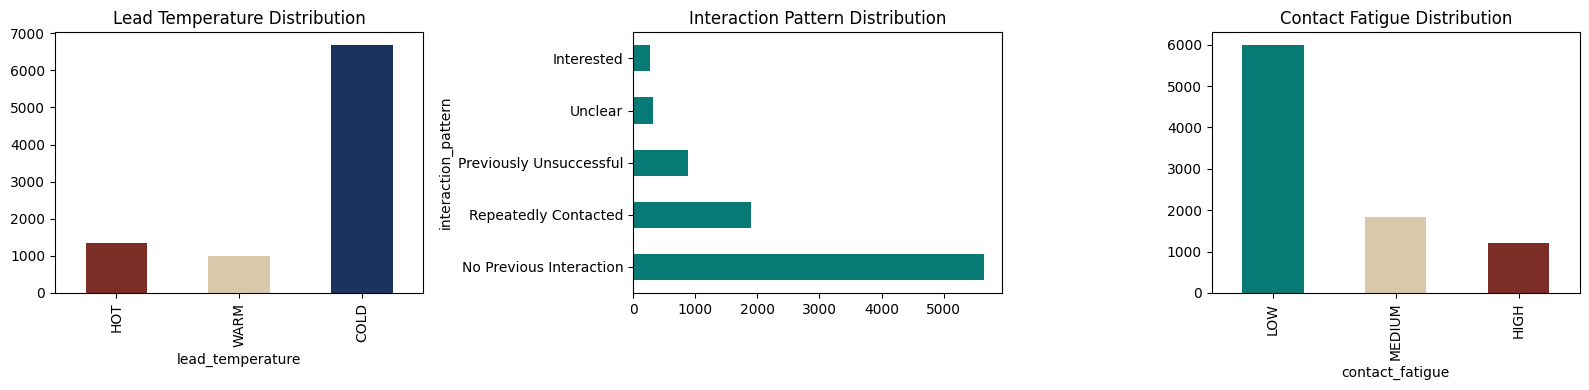

In [27]:
# Quick summary charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

prediction_df["lead_temperature"].value_counts().reindex(["HOT", "WARM", "COLD"]).plot(
    kind="bar", ax=axes[0], color=["#7B2D26", "#D7C9AA", "#19355F"]
)
axes[0].set_title("Lead Temperature Distribution")

prediction_df["interaction_pattern"].value_counts().plot(kind="barh", ax=axes[1], color="#087A75")
axes[1].set_title("Interaction Pattern Distribution")

prediction_df["contact_fatigue"].value_counts().reindex(["LOW", "MEDIUM", "HIGH"]).plot(
    kind="bar", ax=axes[2], color=["#087A75", "#D7C9AA", "#7B2D26"]
)
axes[2].set_title("Contact Fatigue Distribution")

plt.tight_layout()
plt.show()


## 13. Next steps

* The saved artifacts in `../models/` (preprocessor + all trained models)
  and `../outputs/final_predictions.csv` / `top_priority_customers.csv` are
  used directly by the Streamlit dashboard:

  ```bash
  streamlit run app/streamlit_app.py
  ```

* For a fully repeatable, scripted run (e.g. for grading), use:

  ```bash
  python train_and_evaluate.py
  ```

  which performs everything in this notebook end-to-end and regenerates all
  files in `outputs/` and `models/`.

* See `README.md` for the full write-up (architecture, `duration`
  discussion, limitations, future improvements) and `PROJECT_OVERVIEW.md`
  for a short, plain-language summary of the whole system.
